# 1. Import setup & Installation

In [1]:
%pip install xgboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.6/57.6 MB 35.9 MB/s  0:00:016m0:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 206.6/206.6 MB 32.3 MB/s  0:00:06m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [xgboost]m1/2 [xgboost]
Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

from xgboost import XGBRegressor

from sklearn.metrics import mean_absolute_error, mean_squared_error

import warnings
warnings.filterwarnings("ignore")

DATA_DIR = Path("../data/processed")
PROCESSED_DIR = Path("../data/processed")
MODELS_DIR = Path("../models")

MODELS_DIR.mkdir(parents=True, exist_ok=True)

print("XGBoost Environment Ready!")

XGBoost Environment Ready!


# 2. Load Daily Sales Data
We'll use the same M5 dataset and aggregate sales across all products and stores.

In [3]:
CALENDAR_PATH = DATA_DIR / "calendar_cleaned.csv"
SALES_PATH = Path("../data/raw/m5/sales_train_validation.csv")

calendar = pd.read_csv(CALENDAR_PATH, parse_dates=["date"])

sales_header = pd.read_csv(SALES_PATH, nrows=0)
daily_columns = [
    col for col in sales_header.columns
    if col.startswith("d_")
]

daily_sales = pd.Series(0, index=daily_columns, dtype="int64")

for chunk in pd.read_csv(SALES_PATH, chunksize=500):
    daily_sales = daily_sales.add(
        chunk[daily_columns].sum(),
        fill_value=0
    )

daily_ts = pd.DataFrame({
    "date": calendar.set_index("d").loc[daily_columns, "date"].values,
    "sales": daily_sales.values
})

daily_ts = daily_ts.set_index("date").sort_index()

print("Dataset Shape:", daily_ts.shape)
print("Date Range:", daily_ts.index.min(), "to", daily_ts.index.max())
print("Missing Values:", daily_ts.isnull().sum().sum())

Dataset Shape: (1913, 1)
Date Range: 2011-01-29 00:00:00 to 2016-04-24 00:00:00
Missing Values: 0


# 3. Train-Test Split
Same 90-day test period as our previous models.

In [4]:
test_size = 90

train = daily_ts["sales"].iloc[:-test_size].copy()
test = daily_ts["sales"].iloc[-test_size:].copy()

print("Training Observations:", len(train))
print("Testing Observations:", len(test))

print("Training Period:", train.index.min(), "to", train.index.max())
print("Testing Period:", test.index.min(), "to", test.index.max())

Training Observations: 1823
Testing Observations: 90
Training Period: 2011-01-29 00:00:00 to 2016-01-25 00:00:00
Testing Period: 2016-01-26 00:00:00 to 2016-04-24 00:00:00


# 4. Feature Engineering
XGBoost doesn't understand time-series patterns automatically. We'll create features that help it learn demand behaviour.

We'll use:
- Lag features: Previous 1, 7, 14 and 28 days' sales.
- Rolling features: Previous 7 and 28 days' average sales.
- Calendar features: Day, month, weekday and year.

In [5]:
def create_features(data):
    df = pd.DataFrame(index=data.index)
    df["sales"] = data

    # Calendar features
    df["dayofweek"] = df.index.dayofweek
    df["day"] = df.index.day
    df["month"] = df.index.month
    df["year"] = df.index.year
    df["dayofyear"] = df.index.dayofyear
    df["is_weekend"] = (df.index.dayofweek >= 5).astype(int)

    # Lag features
    for lag in [1, 7, 14, 28]:
        df[f"lag_{lag}"] = df["sales"].shift(lag)

    # Rolling features (shifted to avoid leakage)
    df["rolling_mean_7"] = df["sales"].shift(1).rolling(7).mean()
    df["rolling_mean_28"] = df["sales"].shift(1).rolling(28).mean()
    df["rolling_std_7"] = df["sales"].shift(1).rolling(7).std()

    return df


feature_data = create_features(train)

feature_data = feature_data.dropna()

print("Feature Dataset Shape:", feature_data.shape)
display(feature_data.head())

Feature Dataset Shape: (1795, 14)


,sales,dayofweek,day,month,year,dayofyear,is_weekend,lag_1,lag_7,lag_14,lag_28,rolling_mean_7,rolling_mean_28,rolling_std_7
date,,,,,,,,,,,,,,
2011-02-26,29908,5,26,2,2011,57,1,22529.0,31689.0,34833.0,32631.0,24143.142857,26238.678571,4576.628250
2011-02-27,28707,6,27,2,2011,58,1,29908.0,29283.0,36380.0,31749.0,23888.714286,26141.428571,4113.263859
2011-02-28,21240,0,28,2,2011,59,0,28707.0,23966.0,21804.0,23783.0,23806.428571,26032.785714,3991.319742
2011-03-01,22872,1,1,3,2011,60,0,21240.0,20501.0,24070.0,25412.0,23417.000000,25941.964286,4104.536312
2011-03-02,22046,2,2,3,2011,61,0,22872.0,20757.0,21443.0,19146.0,23755.714286,25851.250000,3917.358537


# 5. Prepare Training Data
Separate predictors (X) and target (y).

In [6]:
X_train = feature_data.drop(columns=["sales"])
y_train = feature_data["sales"]

print("X_train Shape:", X_train.shape)
print("y_train Shape:", y_train.shape)
print("Feature Columns:")
print(list(X_train.columns))

X_train Shape: (1795, 13)
y_train Shape: (1795,)
Feature Columns:
['dayofweek', 'day', 'month', 'year', 'dayofyear', 'is_weekend', 'lag_1', 'lag_7', 'lag_14', 'lag_28', 'rolling_mean_7', 'rolling_mean_28', 'rolling_std_7']


In [7]:
xgb_model = XGBRegressor(
    n_estimators=500,
    learning_rate=0.03,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

print("XGBoost Model Training Completed!")

XGBoost Model Training Completed!


# 5. 90-Day Recursive Forecasting with XGBoost

In [8]:
history = train.copy()
xgb_predictions = []

for current_date in test.index:

    history_with_date = pd.concat([
        history,
        pd.Series(index=[current_date], dtype=float)
    ])

    current_features = create_features(history_with_date).iloc[[-1]]
    current_features = current_features.drop(columns=["sales"])

    prediction = xgb_model.predict(current_features)[0]
    prediction = max(0.0, float(prediction))

    xgb_predictions.append(prediction)
    history.loc[current_date] = prediction

xgb_predictions = pd.Series(
    xgb_predictions,
    index=test.index,
    name="XGBoost_Forecast"
)

print("XGBoost Forecast Shape:", xgb_predictions.shape)
print("\nFirst 10 Forecast Values:")
print(xgb_predictions.head(10))

XGBoost Forecast Shape: (90,)

First 10 Forecast Values:
date
2016-01-26    31321.162109
2016-01-27    30623.560547
2016-01-28    32945.375000
2016-01-29    37532.437500
2016-01-30    48554.652344
2016-01-31    46205.257812
2016-02-01    38667.000000
2016-02-02    37737.929688
2016-02-03    37726.750000
2016-02-04    36473.843750
Name: XGBoost_Forecast, dtype: float64


# 6. XGBoost Model Evaluation

In [9]:
xgb_mae = mean_absolute_error(test, xgb_predictions)

xgb_rmse = np.sqrt(mean_squared_error(test, xgb_predictions))

xgb_wmape = (
    np.sum(np.abs(test - xgb_predictions)) / np.sum(test)
) * 100

print("XGBoost Model Performance")
print("-------------------------")
print("MAE:", round(xgb_mae, 2))
print("RMSE:", round(xgb_rmse, 2))
print("WMAPE:", round(xgb_wmape, 2), "%")

XGBoost Model Performance
-------------------------
MAE: 2615.99
RMSE: 3452.68
WMAPE: 6.25 %


XGBoost has the lowest error across all three metrics on our 90-day holdout.

# 7. XGBoost Forecast Visualization
Visualizing Actual vs Predicted Sales

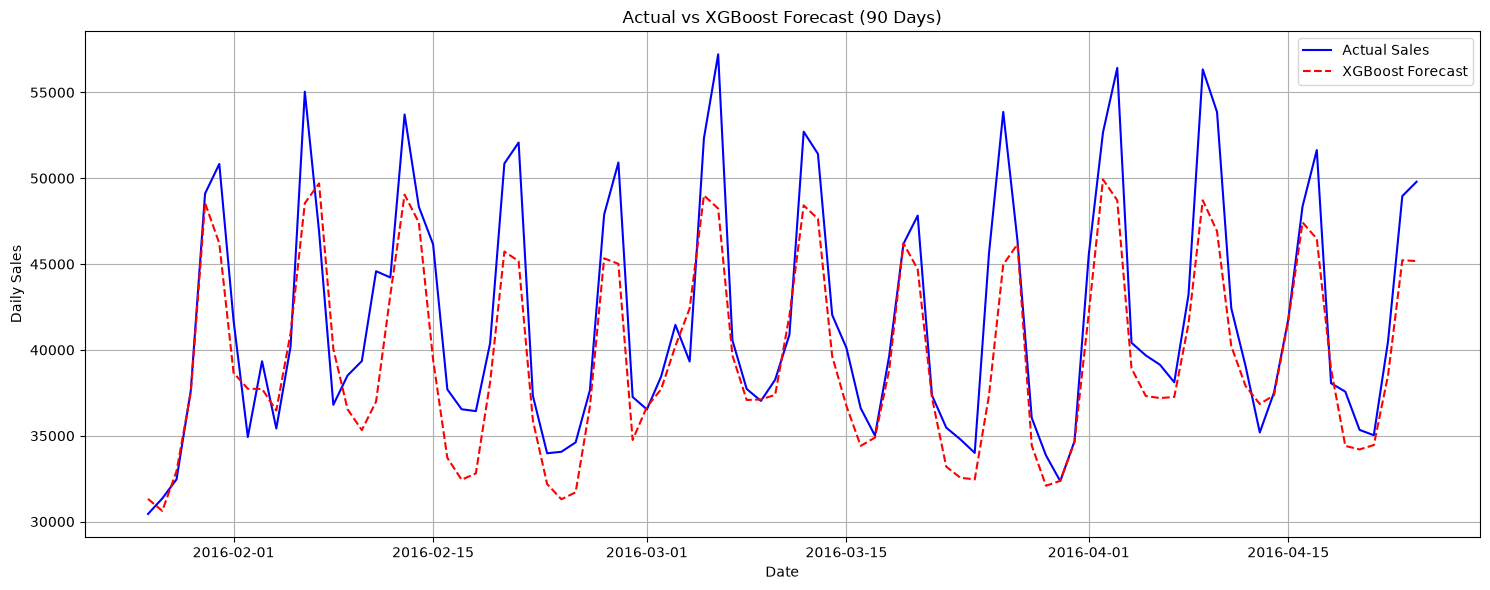

In [10]:
plt.figure(figsize=(15, 6))

plt.plot(test.index, test.values,
         label="Actual Sales", color="blue")

plt.plot(xgb_predictions.index, xgb_predictions.values,
         label="XGBoost Forecast", color="red", linestyle="--")

plt.title("Actual vs XGBoost Forecast (90 Days)")
plt.xlabel("Date")
plt.ylabel("Daily Sales")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# 8. XGBoost Feature Importance
Feature Importance Analysis
Let's identify which features contributed most to the model's predictions.

,Feature,Importance
9,lag_28,0.437678
7,lag_7,0.138551
5,is_weekend,0.128765
0,dayofweek,0.074142
10,rolling_mean_7,0.040508
1,day,0.036375
6,lag_1,0.033390
8,lag_14,0.029120
4,dayofyear,0.023796
12,rolling_std_7,0.019913


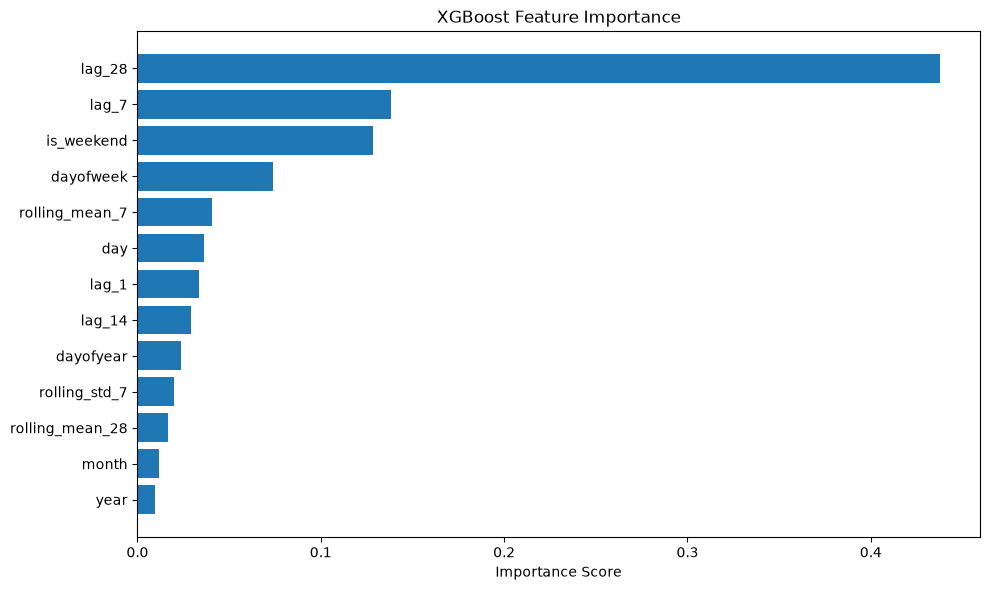

In [11]:
importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": xgb_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance", ascending=False
)

display(importance)

plt.figure(figsize=(10, 6))
plt.barh(importance["Feature"], importance["Importance"])
plt.gca().invert_yaxis()
plt.title("XGBoost Feature Importance")
plt.xlabel("Importance Score")
plt.tight_layout()
plt.show()

### Feature Importance Observations
- lag_28 was the most influential feature, with an importance score of 0.4377.
- lag_7 was the second most important feature, indicating the relevance of weekly sales patterns.
- Weekend and day-of-week features also contributed significantly to predictions.
- Recent sales trends captured through rolling statistics provided additional predictive information.
- Calendar features such as month and year had relatively lower importance.

Overall, the model relies heavily on historical sales patterns, particularly sales from 28 days earlier.

# 8. Saving XGBoost Model

In [13]:
import joblib

joblib.dump(
    xgb_model,
    MODELS_DIR / "xgboost_model.pkl"
)

print("XGBoost Model Saved Successfully!")

XGBoost Model Saved Successfully!


# Exporting XGBoost Forecast

In [14]:
xgb_forecast_df = pd.DataFrame({
    "Actual": test,
    "XGBoost_Forecast": xgb_predictions
})

xgb_forecast_df.to_csv(
    PROCESSED_DIR / "xgboost_forecast.csv"
)

print("XGBoost Forecast Saved Successfully!")
print("Shape:", xgb_forecast_df.shape)

XGBoost Forecast Saved Successfully!
Shape: (90, 2)
